(replication-across-studies)=
# Replication across studies

Most genes that one study finds are not found by the next: of the genes that one
dataset of Alzheimer's disease found differentially expressed, over 85% were not
found in any of 16 others [@nakatsuka2025]. Some are changes the other studies were
too small to detect, others belong to one study alone. This page measures how well
six cohorts replicate each other, and which of their genes replicate: the genes found
in k cohorts, π₁ between cohorts, combined p-values against the p-value that a change
replicates, SumRank [@nakatsuka2025], and the prediction of cases in a cohort left
out. [Meta-analysis](../statistics/meta_analysis.md) explains the statistics.

The cohorts are the six simulated ones of [Combine studies](combine_studies.ipynb),
aligned and analysed as there, each by {api}`limma_voom` on its own. The simulation
knows which monocyte genes the disease changes in every cohort, and which genes one
cohort alone changes.

In [1]:
import textwrap
import warnings

import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool.cube import CubeCollection
from cytepool.design import Design
from cytepool.differential_expression import limma_voom
from cytepool.held_out_prediction import held_out_prediction
from cytepool.io import read_cube
from cytepool.meta_analysis import (
    align_study_results,
    differential_expression_meta_analysis,
)
from cytepool.plotting import (
    plot_held_out_auc,
    plot_replicated_genes,
    plot_study_agreement,
    plot_sumrank,
)
from cytepool.replication import differential_expression_replication
from cytepool.stats.combined_p_values import (
    combine_p_values,
    partial_conjunction,
)
from cytepool.stats.multiple_testing import adjust_p_values
from cytepool.sumrank import differential_expression_sumrank

studies = [f"cohort_{i}" for i in range(1, 7)]
cubes = {study: read_cube(f"simulated_{study}.cube.zarr") for study in studies}
cd4_subsets = {"CD4 naive": "CL:0000624", "CD4 memory": "CL:0000624"}
collection = CubeCollection(cubes, group_mapping={"cohort_4": cd4_subsets})
contrast, monocytes = "case_vs_control", "CL:0001054"
results = {}
for study in collection.studies:
    cube = collection.aligned_cube(study)
    design = Design(
        cube.samples,
        "~ condition",
        levels={"condition": ["control", "case"]},
        contrasts={contrast: "conditioncase"},
    )
    results[study] = limma_voom(cube, design)

truth = np.load("simulated_cohorts_truth.npz")
genes = truth["feature_id"]
cell_type = list(truth["cell_ontology_ids"]).index(monocytes)
changed = truth["true_log2_fold_change"][:, cell_type] != 0  # cohorts x genes
everywhere = genes[changed.all(axis=0)]
one_cohort = genes[changed.sum(axis=0) == 1]
unchanged = genes[~changed.any(axis=0)]
truth_sets = (everywhere, one_cohort, unchanged)
columns = ("every cohort", "one cohort", "unchanged")


def by_truth(feature_ids, adjusted):
    called = np.asarray(feature_ids)[np.asarray(adjusted) < 0.05]
    return [np.isin(called, kind).sum() for kind in truth_sets]


def row(label, values):
    print(f"{label:<36}{values[0]:>13}{values[1]:>12}{values[2]:>11}")


print(f"CytePool {cytepool.__version__}, numpy {np.__version__}")
row("monocyte genes, adjusted p < 0.05", columns)
for study, result in results.items():
    table = result.table(monocytes, contrast)
    label = f"{study} ({cubes[study].n_samples} donors)"
    row(label, by_truth(table["feature_id"], table["adjusted_p_value"]))
row("changed by the simulation", (everywhere.size, one_cohort.size, ""))

CytePool 0.1.dev55+g941b81fb5, numpy 2.5.4
monocyte genes, adjusted p < 0.05    every cohort  one cohort  unchanged
cohort_1 (60 donors)                           62          10          1
cohort_2 (32 donors)                           38          10          4
cohort_3 (24 donors)                           22           7          1
cohort_4 (16 donors)                           17           7          0
cohort_5 (12 donors)                           26           2          0
cohort_6 (20 donors)                           22           7          2
changed by the simulation                     100          60           


Each cohort finds 17 to 62 of the 100 genes that the disease changes in every cohort,
the most in the largest, and 2 to 10 of the 10 genes it changes alone.

## Genes found in k cohorts

{api}`differential_expression_replication` reads one cell type and contrast of every
cohort, lined up gene by gene, and counts the cohorts that find each gene (adjusted
p-value below 0.05) and in which direction. {api}`plot_replicated_genes` draws how
many genes each number of cohorts finds, as the paper that introduced SumRank counts
them [@nakatsuka2025].

monocyte genes found: 133
  by one cohort only: 73
    changed in every cohort: 22
    changed in that cohort alone: 43
    unchanged: 8


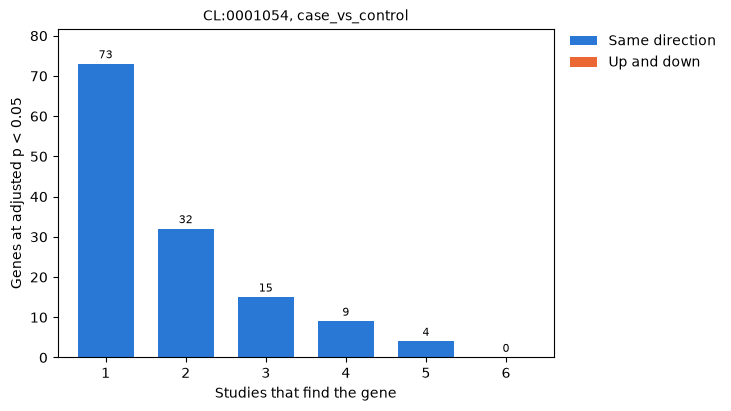

In [2]:
replication = differential_expression_replication(
    collection, results, group=monocytes, contrast=contrast
)
found = replication.genes
once = found["feature_id"][found["n_found"] == 1]
every, own, none = (np.isin(once, kind).sum() for kind in truth_sets)
print(f"monocyte genes found: {np.count_nonzero(found['n_found'])}")
print(f"  by one cohort only: {once.size}")
print(f"    changed in every cohort: {every}")
print(f"    changed in that cohort alone: {own}")
print(f"    unchanged: {none}")
plot_replicated_genes(replication)
plt.show()

Most genes are found by one cohort only, 73 of the 133 found, and none by all six. Of
those 73, 43 belong to that cohort alone, but 22 change in every cohort and the other
cohorts missed them: a gene that one cohort finds and the next does not is not
necessarily a change of one cohort.

## How well each cohort replicates the others

A gene that one cohort finds and another does not may still change in the other, by
too little for it to detect. π₁ of the second cohort's p-values for the genes the
first finds, one minus Storey's estimate of the proportion of them without an effect
[@storey2003], estimates the share that change in the second cohort, whether it finds
them or not. {api}`plot_study_agreement` draws it for every pair of cohorts. Each
entry is computed from the few dozen genes that one cohort finds; on so few p-values
qvalue's default estimate of π₀, a smoother read at λ = 0.95, is unsteady, and a
single λ of 0.5 is steadier (`null_proportion={"lambdas": 0.5}`).

pi1 by qvalue's smoother: 0.00 to 1.00, mean 0.72
pi1 by lambda 0.5: 0.47 to 1.00, mean 0.73
share of the genes found by both cohorts: mean 0.32
share with the same sign: 0.73 to 1.00


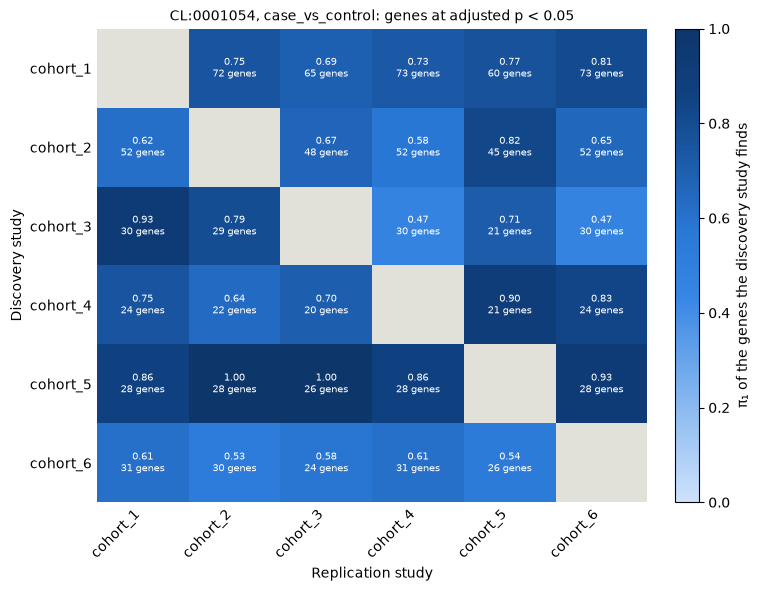

In [3]:
steady = differential_expression_replication(
    collection,
    results,
    group=monocytes,
    contrast=contrast,
    null_proportion={"lambdas": 0.5},
)
pairs = steady.study_pairs
for name, pi1 in (
    ("qvalue's smoother", replication.study_pairs["pi1"]),
    ("lambda 0.5", pairs["pi1"]),
):
    low, high, mean = pi1.min(), pi1.max(), pi1.mean()
    print(f"pi1 by {name}: {low:.2f} to {high:.2f}, mean {mean:.2f}")
both = pairs["n_found_in_both"] / pairs["n_found"]
signs = pairs["sign_agreement"]
print(f"share of the genes found by both cohorts: mean {both.mean():.2f}")
print(f"share with the same sign: {signs.min():.2f} to {signs.max():.2f}")
figure, ax = plt.subplots(figsize=(7.5, 5.8), layout="constrained")
plot_study_agreement(steady, ax=ax)
plt.show()

π₁ lies between 0.47 and 1.00, 0.73 on average: of the genes one cohort finds, most
change in each other cohort, although the other cohort finds only a third of them
itself, on average, and their signs agree for 73% to 100% of them. qvalue's smoother
gave π₁ from 0 to 1 on the same genes. π₁ is not symmetric: it reads the genes of the
discovery cohort in the p-values of the replication cohort, and the genes of the small
cohort_5, its clearest changes, replicate best.

## Combined p-values and replicated changes

{api}`combine_p_values` combines each gene's p-values over the cohorts that tested it
into the p-value of the hypothesis that no cohort changes it: Fisher's method responds
to the strongest cohort [@fisher1932], and Stouffer's, weighted by the square roots of
the cohorts' sizes, to the evidence they share [@stouffer1949; @zaykin2011]; the
replication result holds the latter. A small combined p-value says that some cohort
changes the gene, not that the change replicates. {api}`partial_conjunction` tests
instead whether at least u cohorts change it, in one direction [@benjamini2008]; the
replication result holds it for u = 2. The monocyte genes each finds at a false
discovery rate of 5%, with the random-effects meta-analysis (REML) of
[Combine studies](combine_studies.ipynb) for comparison:

In [4]:
aligned = align_study_results(collection, results, monocytes, contrast)
shape = (collection.n_studies, collection.n_features)
p_values = aligned["p_value"].reshape(shape)
log2_fc = aligned["log2_fold_change"].reshape(shape)
ids, found_ids = collection.features["feature_id"], found["feature_id"]
fisher = combine_p_values(p_values, method="fisher", directions=log2_fc)
in_three = partial_conjunction(p_values, 3, directions=log2_fc)
meta = differential_expression_meta_analysis(results).table(monocytes, contrast)
methods = {
    "Fisher": (ids, adjust_p_values(fisher.p_value, "bh")),
    "Stouffer, weighted": (found_ids, found["adjusted_p_value"]),
    "in at least 2 cohorts": (found_ids, found["replication_adjusted_p_value"]),
    "in at least 3 cohorts": (ids, adjust_p_values(in_three.p_value, "bh")),
    "meta-analysis (REML)": (meta["feature_id"], meta["adjusted_p_value"]),
}
row("genes at adjusted p < 0.05", columns)
for name, (feature_ids, adjusted) in methods.items():
    row(name, by_truth(feature_ids, adjusted))

genes at adjusted p < 0.05           every cohort  one cohort  unchanged
Fisher                                         94          36          3
Stouffer, weighted                             93          19          2
in at least 2 cohorts                          41           0          0
in at least 3 cohorts                           7           0          0
meta-analysis (REML)                           80           0          2


Fisher's method finds 94 of the 100 genes changed in every cohort, and 36 of the 60
genes of single cohorts: one cohort's strong change is enough. Stouffer's method,
which weighs the evidence of every cohort and its direction, keeps 19 of those. The
partial conjunction tests find no gene of a single cohort, at a cost in power: 41
genes in at least 2 cohorts and 7 in at least 3, since the change must be clear in
that many cohorts on its own. The random-effects meta-analysis finds 80, none of a
single cohort.

## SumRank

SumRank asks instead that a gene rank high in most cohorts [@nakatsuka2025]. Each
cohort ranks the genes that every cohort tested by their signed -log10 p-values, and a
gene's normalized ranks are summed over the cohorts, for genes up and, from the other
end, for genes down. If the cohorts ranked the genes at random, the sum of a gene's
ranks over every cohort would follow the Irwin-Hall distribution
[@irwin1927; @hall1927], which gives its p-value.
{api}`differential_expression_sumrank` computes it for one cell type and contrast, and
{api}`plot_sumrank` draws every gene's p-value, the genes in alphabetical order, as the
authors of SumRank draw it.

1,380 genes ranked, by all six cohorts
adjusted p < 0.05                    every cohort  one cohort  unchanged
genes up                                       28           0          1
genes down                                     27           0          0


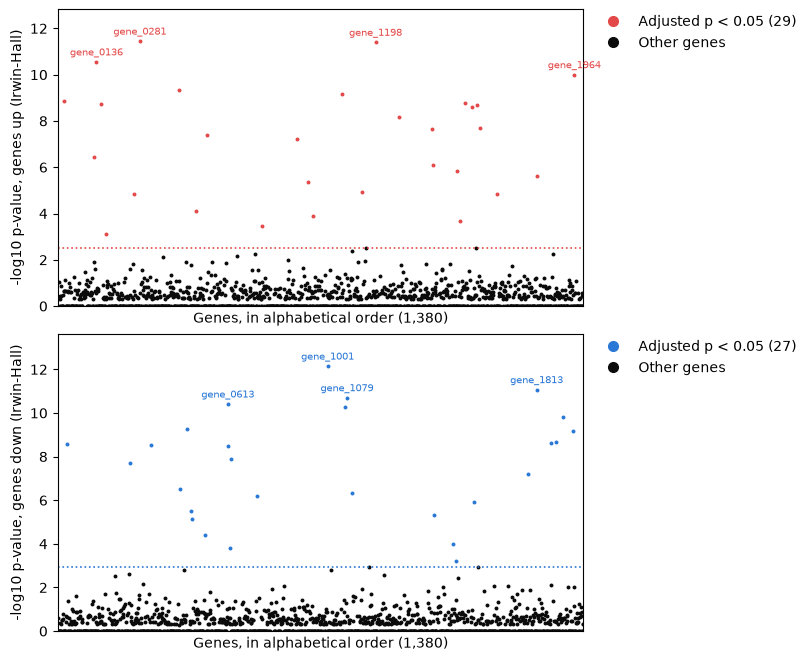

In [5]:
sumrank = differential_expression_sumrank(
    collection, results, group=monocytes, contrast=contrast
)
table = sumrank.table
print(f"{len(table):,} genes ranked, by all six cohorts")
row("adjusted p < 0.05", columns)
for direction in ("up", "down"):
    adjusted = table[f"{direction}_adjusted_p_value"]
    row(f"genes {direction}", by_truth(table["feature_id"], adjusted))
figure, axes = plt.subplots(2, 1, figsize=(8, 6.5), layout="constrained")
plot_sumrank(sumrank, n_labels=4, ax=axes[0])
plot_sumrank(sumrank, direction="down", n_labels=4, ax=axes[1])
plt.show()

SumRank finds 56 genes, 29 up and 27 down, all but one changed in every cohort, and no
gene of a single cohort, which ranks high in that cohort only. It ranks the 1,380
genes that all six cohorts tested: genes that cohort_3 or cohort_5 did not measure,
or that the expression filter of the small cohort_5 left out, are not ranked.

## Summing the best ranks

A cohort can miss a change for reasons of its own, so SumRank can sum each gene's best
ranks only, those of the cohorts that rank it highest: the paper summed every study of
Parkinson's disease, Huntington's disease and schizophrenia, of which there were 3 to
6, and 65% of the 17 studies of Alzheimer's disease and 55% of the 16 of COVID-19,
proportions it chose by cross-validation [@nakatsuka2025]. A sum of the best ranks is
smaller than a sum of uniform ranks, so its Irwin-Hall p-values are too small, as
{api}`differential_expression_sumrank` warns. Its p-values come instead from
permutations: the case and control labels are permuted within each cohort, each
cohort's analysis is run again, and the statistics of every gene in every permutation
make one null distribution [@phipson2010]. Here the best 4 of the 6 cohorts are
summed, with 30 permutations.

In [6]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    irwin_hall = differential_expression_sumrank(
        collection, results, monocytes, contrast, proportion_of_studies=4 / 6
    )
print(textwrap.fill(f"RuntimeWarning: {caught[0].message}", 78), end="\n\n")
permuted = differential_expression_sumrank(
    collection,
    results,
    monocytes,
    contrast,
    proportion_of_studies=4 / 6,
    n_permutations=30,
    permute="condition",
    rng=1,
)
row("up or down, adjusted p < 0.05", columns)
for name, found_by in (
    ("all 6 cohorts, Irwin-Hall", sumrank),
    ("best 4, Irwin-Hall", irwin_hall),
    ("best 4, 30 permutations", permuted),
):
    table = found_by.table
    up, down = table["up_adjusted_p_value"], table["down_adjusted_p_value"]
    row(name, by_truth(table["feature_id"], np.minimum(up, down)))

ranks are too small, as the sum of the best ranks is smaller than a sum of
uniform ranks; the p_value columns hold them, so take p-values from
permutations (n_permutations and permute)



up or down, adjusted p < 0.05        every cohort  one cohort  unchanged
all 6 cohorts, Irwin-Hall                      55           0          1
best 4, Irwin-Hall                             62           7         16
best 4, 30 permutations                        59           0          0


Summed over the best 4 of the 6 cohorts, the Irwin-Hall p-values find 16 unchanged
genes and 7 of single cohorts, as the warning says they would. With permutations, the
same statistics find 59 genes, all changed in every cohort, more than the sum over all
six.

## Prediction in held-out cohorts

Genes that replicate should tell cases from controls in a cohort that had no part in
choosing them. {api}`held_out_prediction` leaves each cohort out in turn, chooses 20
genes up and 20 down in every cell type from the other five, by SumRank and by a
random-effects meta-analysis with the Knapp-Hartung adjustment, as the paper compares
them, scores every donor of the held-out cohort by how high its profiles rank those
genes, as UCell scores them [@andreatta2021], and reports the area under the ROC
curve (AUC) of its cases against its controls [@hanley1982]. {api}`plot_held_out_auc`
draws it for every cohort. The paper chose the proportion of studies summed by
cross-validation; the mean AUC for a few proportions comes first.

proportion of the cohorts summed: mean AUC
  1.0: SumRank 0.92, meta-analysis 0.87
  0.8: SumRank 0.89, meta-analysis 0.87
  0.6: SumRank 0.87, meta-analysis 0.87
  0.4: SumRank 0.92, meta-analysis 0.87


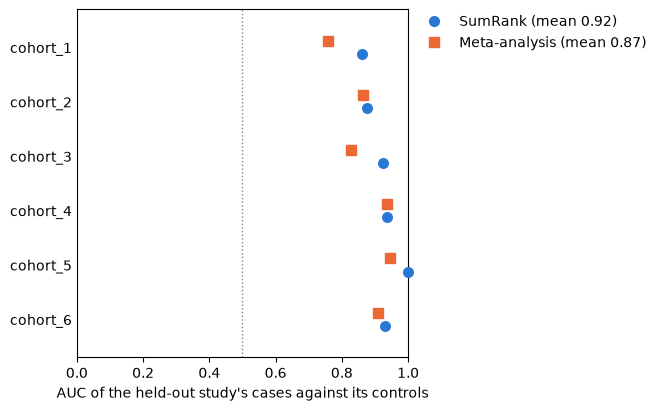

In [7]:
lines = ["proportion of the cohorts summed: mean AUC"]
for proportion in (1.0, 0.8, 0.6, 0.4):
    auc = held_out_prediction(
        collection,
        results,
        contrast,
        "condition",
        "case",
        "control",
        n_genes=20,
        proportion_of_studies=proportion,
    ).auc
    sumrank_auc = np.nanmean(auc["auc"][auc["method"] == "sumrank"])
    meta_auc = np.nanmean(auc["auc"][auc["method"] == "meta_analysis"])
    line = f"SumRank {sumrank_auc:.2f}, meta-analysis {meta_auc:.2f}"
    lines.append(f"  {proportion}: {line}")
print("\n".join(lines))
prediction = held_out_prediction(
    collection, results, contrast, "condition", "case", "control", n_genes=20
)
plot_held_out_auc(prediction)
plt.show()

SumRank's genes predict the held-out cases a little better here, with a mean AUC of
0.92 against 0.87, most clearly in cohort_1 and cohort_3; with six cohorts, the
proportion summed moves the mean AUC between 0.87 and 0.92 only. In the 17 studies of
Alzheimer's disease of the paper, SumRank's genes predicted the left-out datasets with
a mean AUC of 0.78, as did those of the datasets merged into one model with the
dataset as a covariate; those of the inverse-variance meta-analysis 0.74, and the
genes of single datasets 0.67 (its Table 1) [@nakatsuka2025].

## Choices

- **Which genes replicate.** A meta-analysis estimates each gene's change with its
  uncertainty and weighs the cohorts by their precision; with random effects, their
  disagreement widens the interval. A partial conjunction test claims a change in at
  least u cohorts, with a false discovery rate over the genes. SumRank asks that a
  gene rank high in most cohorts, and weighs every cohort alike.
- **Which combination of p-values.** Fisher's method finds genes that any cohort
  changes; Stouffer's, weighted by the square roots of the cohorts' sizes, the default
  of {api}`differential_expression_replication`, rewards evidence the cohorts share;
  neither says that a change replicates, which {api}`partial_conjunction` tests
  (`at_least`, and `conjunction_method` for Simes's, Fisher's or Stouffer's
  combination).
- **π₁ on few genes.** Estimate π₀ at one λ, such as 0.5, or with qvalue's bootstrap
  (`null_proportion={"method": "bootstrap"}`), when the cohorts find few genes.
- **SumRank's proportion and p-values.** Summing every cohort, the Irwin-Hall p-values
  serve; summing fewer needs permutations (`n_permutations` and `permute`), each of
  which runs every cohort's analysis again, and designs with random effects cannot be
  permuted. SumRank ranks only the genes that every cohort tested, so a cohort with a
  short panel of genes or a strict expression filter shortens the list for all.
- **Held-out prediction.** `n_genes` sets how many genes up and down are chosen in each
  cell type, and `groups` the cell types scored; an AUC below 0.5 says the genes
  predict the wrong direction.